# Khám phá và Xử lý Dữ liệu (EDA) — Superstore Sales Dataset

Notebook này thực hiện đầy đủ quy trình EDA (25% điểm):
1. Đọc và kiểm tra chất lượng dữ liệu (`Sample - Superstore.csv`).
2. Làm sạch dữ liệu thiếu, dữ liệu trùng lặp, xử lý ngoại lệ và định dạng lại cột thời gian/doanh thu.
3. Thống kê tổng hợp bằng `groupby()` và `pd.pivot_table()`.
4. Trực quan hóa khám phá ban đầu bằng Plotly.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px

sys.path.append(str(Path('..').resolve()))
from data.loader import audit_raw_data, clean_superstore_data, load_raw_data
from data.analytics import (
    compute_rfm_segments,
    forecast_monthly_sales,
    pivot_region_category,
    pivot_year_segment,
    run_market_basket_apriori,
    summarize_by_category,
    summarize_by_region,
    summarize_by_time,
)

## 1. Đọc dữ liệu và Kiểm tra chất lượng (Data Audit)

In [2]:
raw_df = load_raw_data('../Sample - Superstore.csv')
print('Kích thước dữ liệu gốc:', raw_df.shape)
raw_df.head()

Kích thước dữ liệu gốc: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
audit = audit_raw_data(raw_df)
for k, v in audit.items():
    print(f'{k}: {v}')

rows: 9994
columns: 21
missing_total: 0
missing_by_column: {}
full_duplicates: 0
business_duplicates: 1
invalid_dates: 0
invalid_ship_sequence: 0
sales_iqr_bounds: (-271.71, 498.93)
sales_outliers_count: 1167
profit_iqr_bounds: (-39.7241, 70.8169)
profit_outliers_count: 1881


## 2. Làm sạch dữ liệu, Định dạng cột và Xử lý ngoại lệ

In [4]:
clean_df = clean_superstore_data(raw_df, cap_outliers=False)
print('Kích thước sau làm sạch:', clean_df.shape)
clean_df[['Order Date', 'Ship Date', 'Postal Code', 'Sales', 'Quantity', 'Discount', 'Profit']].info()

Kích thước sau làm sạch: (9993, 30)
<class 'pandas.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Order Date   9993 non-null   datetime64[us]
 1   Ship Date    9993 non-null   datetime64[us]
 2   Postal Code  9993 non-null   str           
 3   Sales        9993 non-null   float64       
 4   Quantity     9993 non-null   int64         
 5   Discount     9993 non-null   float64       
 6   Profit       9993 non-null   float64       
dtypes: datetime64[us](2), float64(3), int64(1), str(1)
memory usage: 596.6 KB


In [5]:
clean_df[['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Days']].describe().round(2)

,Sales,Quantity,Discount,Profit,Shipping_Days
count,9993.00,9993.00,9993.00,9993.00,9993.00
mean,229.85,3.79,0.16,28.66,3.96
std,623.28,2.23,0.21,234.27,1.75
min,0.44,1.00,0.00,-6599.98,0.00
25%,17.28,2.00,0.00,1.73,3.00
50%,54.48,3.00,0.20,8.67,4.00
75%,209.94,5.00,0.20,29.36,5.00
max,22638.48,14.00,0.80,8399.98,7.00


### Lọc dữ liệu theo điều kiện

In [6]:
loss_df = clean_df[clean_df['Profit'] < 0]
high_disc_loss = clean_df[(clean_df['Discount'] > 0.2) & (clean_df['Profit'] < 0)]
print(f'Số dòng giao dịch thua lỗ: {len(loss_df)}')
print(f'Số dòng chiết khấu > 20% gây lỗ: {len(high_disc_loss)}')

Số dòng giao dịch thua lỗ: 1870
Số dòng chiết khấu > 20% gây lỗ: 1347


## 3. Thống kê & Tổng hợp bằng GroupBy và Pivot Table

In [7]:
print('--- GroupBy theo Năm ---')
display(summarize_by_time(clean_df, freq='Y'))

print('--- GroupBy theo Khu vực ---')
display(summarize_by_region(clean_df))

print('--- GroupBy theo Danh mục ---')
display(summarize_by_category(clean_df))

--- GroupBy theo Năm ---
--- GroupBy theo Khu vực ---
--- GroupBy theo Danh mục ---


,Period,Total_Sales,Total_Profit,Order_Count,Total_Quantity,Profit_Margin_Pct
0,2014,483966.1261,49556.0329,969,7579,10.239566
1,2015,470532.5090,61618.6037,1038,7979,13.095504
2,2016,609205.5980,81795.1743,1315,9837,13.426530
3,2017,733215.2552,93439.2696,1687,12476,12.743771


,Region,Total_Sales,Total_Profit,Order_Count,Total_Quantity,Profit_Margin_Pct
3,West,725457.8245,108418.4489,1611,12266,14.944831
1,East,678499.8680,91534.8388,1401,10616,13.490767
0,Central,501239.8908,39706.3625,1175,8780,7.921629
2,South,391721.9050,46749.4303,822,6209,11.934342


,Category,Sub-Category,Total_Sales,Total_Profit,Order_Count,Total_Quantity,Profit_Margin_Pct
16,Technology,Phones,330007.0540,44515.7306,814,3289,13.489327
1,Furniture,Chairs,328167.7310,26602.2251,576,2354,8.106289
11,Office Supplies,Storage,223843.6080,21278.8264,777,3158,9.506113
3,Furniture,Tables,206965.5320,-17725.4811,307,1241,-8.564460
6,Office Supplies,Binders,203412.7330,30221.7633,1316,5974,14.857361
15,Technology,Machines,189238.6310,3384.7569,112,440,1.788618
13,Technology,Accessories,167380.3180,41936.6357,718,2976,25.054700
14,Technology,Copiers,149528.0300,55617.8249,68,234,37.195585
0,Furniture,Bookcases,114879.9963,-3472.5560,224,868,-3.022768
4,Office Supplies,Appliances,107532.1610,18138.0054,451,1729,16.867517


In [8]:
print('--- Pivot Table: Khu vực x Danh mục (Doanh thu) ---')
display(pivot_region_category(clean_df).round(2))

print('--- Pivot Table: Năm x Phân khúc (Doanh thu & Số đơn hàng) ---')
display(pivot_year_segment(clean_df).round(2))

--- Pivot Table: Khu vực x Danh mục (Doanh thu) ---
--- Pivot Table: Năm x Phân khúc (Doanh thu & Số đơn hàng) ---


Category,Furniture,Office Supplies,Technology,Tổng cộng
Region,,,,
Central,163797.16,167026.42,170416.31,501239.89
East,208009.83,205516.06,264973.98,678499.87
South,117298.68,125651.31,148771.91,391721.90
West,252612.74,220853.25,251991.83,725457.82
Tổng cộng,741718.42,719047.03,836154.03,2296919.49


Order ID                            Sales                       
Segment    Consumer Corporate Home Office   Consumer  Corporate Home Office
Order_Year                                                                 
2014            524       287         158  266096.81  128434.87    89434.44
2015            535       312         191  266535.93  128757.31    75239.27
2016            651       422         242  296863.90  207106.36   105235.34
2017            876       493         318  331904.70  241847.82   159462.73

## 4. Trực quan hóa dữ liệu bắt buộc (So sánh, Phân phối, Xu hướng, Tổng hợp)

<cell_14>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


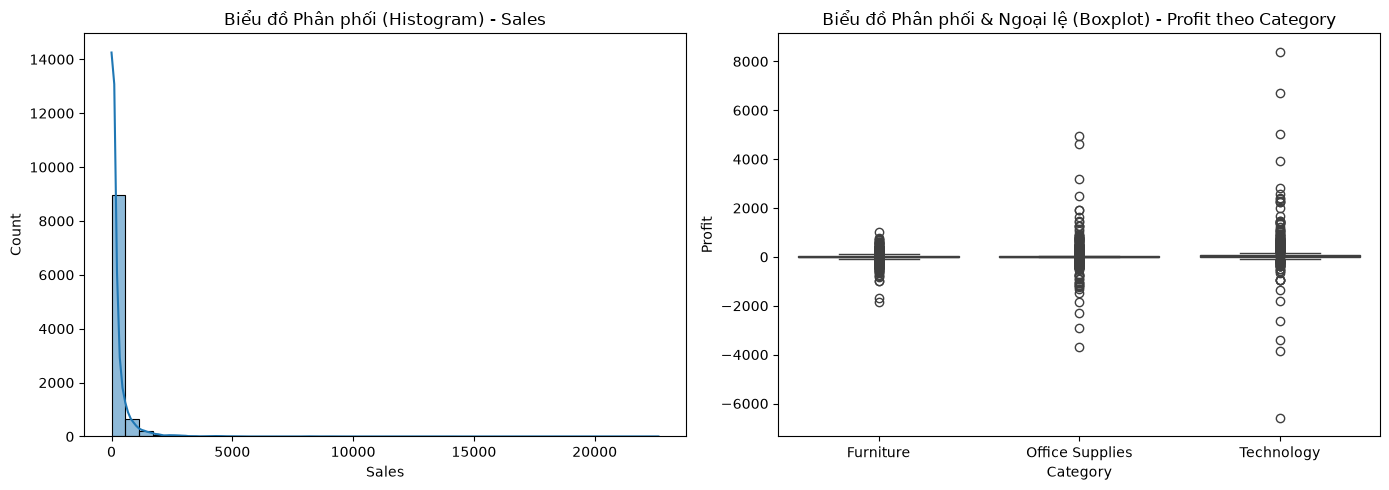

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(clean_df['Sales'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Biểu đồ Phân phối (Histogram) - Sales')
sns.boxplot(data=clean_df, x='Category', y='Profit', ax=axes[1])
axes[1].set_title('Biểu đồ Phân phối & Ngoại lệ (Boxplot) - Profit theo Category')
plt.tight_layout()
plt.show()

In [10]:
# Biểu đồ so sánh (Bar) và biểu đồ tổng hợp (Stacked/Grouped Bar)
reg_df = summarize_by_region(clean_df)
px.bar(reg_df, x='Region', y='Total_Sales', color='Region', title='Biểu đồ So sánh Doanh thu theo Khu vực').show()

cat_seg = clean_df.groupby(['Segment', 'Category'], as_index=False)['Sales'].sum()
px.bar(cat_seg, x='Segment', y='Sales', color='Category', barmode='stack', title='Biểu đồ Tổng hợp (Stacked Bar) Segment x Category').show()

Figure(Biểu đồ So sánh Doanh thu theo Khu vực)

Figure(Biểu đồ Tổng hợp (Stacked Bar) Segment x Category)

In [11]:
monthly_df = summarize_by_time(clean_df, freq='M')
fig = px.line(monthly_df, x='Period', y=['Total_Sales', 'Total_Profit'], title='Biểu đồ Xu hướng Doanh thu & Lợi nhuận theo Tháng')
fig.show()

Figure(Biểu đồ Xu hướng Doanh thu & Lợi nhuận theo Tháng)

In [12]:
fig_disc = px.scatter(
    clean_df,
    x='Discount',
    y='Profit',
    color='Category',
    title='Tác động của Chiết khấu đến Lợi nhuận'
)
fig_disc.add_hline(y=0, line_dash='dash', line_color='red')
fig_disc.show()

Figure(Tác động của Chiết khấu đến Lợi nhuận)